<a href="https://colab.research.google.com/github/muhammadabdullahz/Local-Projections-jorda-taylor/blob/main/notebooks/jorda_taylor_lp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Overview
This independent replication project examines the effects of monetary policy shocks on U.S. inflation and unemployment. Following Jordà and Taylor, it reproduces Figures 5 and 6 using quarterly and monthly macroeconomic data to estimate dynamic impulse responses.

The analysis applies local projections (LP) to estimate the response of the consumer price index (CPI) to Romer-Romer shocks and instrumental variables local projections (LP-IV) to estimate the unemployment response, treating the federal funds rate as endogenous and instrumenting it with contemporaneous and lagged monetary policy shocks.

The implementation combines Frisch-Waugh-Lovell residualisation, two-stage least squares (2SLS), Newey-West HAC standard errors, joint Wald tests and Bonferroni-adjusted confidence bands. Python estimates are validated against the published Stata results.

### Data Preparation and Loading

We begin by importing the Python libraries required for data manipulation, econometric estimation, statistical inference and visualization. We then load the Jordà–Taylor (2025) replication dataset from Excel for the empirical analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from google.colab import drive

drive.mount('/content/drive')
PATH = '/content/drive/MyDrive/LocalProjections/JT2025_Data.xlsx'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# The sheet has two header rows: row 1 = long names, row 2 = mnemonics, data from row 3
header_rows = pd.read_excel(PATH, sheet_name='Ex5', header=None, nrows=2)
raw = pd.read_excel(PATH, sheet_name='Ex5', header=1)   # use the mnemonic row as column names

raw = raw.rename(columns={raw.columns[0]: 'date'})
raw.columns = raw.columns.str.strip()

# Dates look like '1960q1' -> quarterly PeriodIndex
raw.index = pd.PeriodIndex(raw['date'].astype(str).str.upper(), freq='Q')
raw = raw.drop(columns='date')

# Dictionary of long names (for plot titles)
long_names = dict(zip(header_rows.iloc[1, 1:], header_rows.iloc[0, 1:]))

print(raw.shape)
raw.head()

(224, 7)


,rr_shock,lcpi,dlcpi,stir,dstir,lrgdp,dlrgdp
date,,,,,,,
1960Q1,NaN,-1.748872,1.635790,3.93,-0.06,5.082913,9.778676
1960Q2,NaN,-1.746232,1.056242,3.70,-0.23,5.075729,-2.873481
1960Q3,NaN,-1.742627,1.442099,2.94,-0.76,5.074956,-0.309442
1960Q4,NaN,-1.739547,1.231956,2.30,-0.64,5.060852,-5.641609
1961Q1,NaN,-1.737385,0.864697,2.00,-0.30,5.063770,1.167127


### Defining the Estimation Sample

We restrict the dataset to 1985Q1–2007Q4, following the original Stata implementation. The log CPI and log real GDP variables are rescaled by 100 to facilitate interpretation of subsequent differences in percentage terms.

In [3]:
# Stata cuts the sample BEFORE building lags/leads, so we do the same
df = raw.loc['1985Q1':'2007Q4'].copy()

# Scale to percent, as in the .do file (dlcpi and dlrgdp are left as they are)
df['lcpi']  = 100 * df['lcpi']
df['lrgdp'] = 100 * df['lrgdp']

print("Observations in sample:", len(df))   # should be 92
df.head()

Observations in sample: 92


,rr_shock,lcpi,dlcpi,stir,dstir,lrgdp,dlrgdp
date,,,,,,,
1985Q1,0.086373,-56.697279,4.574394,8.48,-0.790001,600.230551,4.163175
1985Q2,-0.146462,-56.080401,2.467513,7.92,-0.559999,601.100874,3.481355
1985Q3,0.250760,-55.502135,2.313066,7.90,-0.020000,602.635956,6.140340
1985Q4,0.073238,-54.925466,2.306676,8.10,0.200000,603.257179,2.484962
1986Q1,-0.094937,-54.438239,1.948905,7.83,-0.270000,604.279518,4.089307


### Checking Missing Observations

We examine missing values in both the full dataset and the restricted estimation sample. This ensures that the variables required for the subsequent Local Projection regressions are properly observed.

In [4]:
print("Missing values, full data:")
print(raw.isna().sum(), "\n")

print("Missing values, estimation sample:")
print(df.isna().sum(), "\n")

df.describe().round(3)

Missing values, full data:
rr_shock    68
lcpi         0
dlcpi        0
stir         0
dstir        0
lrgdp        0
dlrgdp       0
dtype: int64 

Missing values, estimation sample:
rr_shock    0
lcpi        0
dlcpi       0
stir        0
dstir       0
lrgdp       0
dlrgdp      0
dtype: int64 



,rr_shock,lcpi,dlcpi,stir,dstir,lrgdp,dlrgdp
count,92.000,92.000,92.000,92.000,92.000,92.000,92.000
mean,0.052,-28.256,2.425,5.098,-0.052,639.472,3.378
std,0.277,15.296,0.912,2.178,0.472,23.933,2.529
min,-0.571,-56.697,0.653,1.000,-1.370,600.231,-4.007
25%,-0.095,-39.312,1.773,3.490,-0.263,617.850,1.717
50%,0.034,-26.566,2.279,5.280,-0.010,637.631,3.567
75%,0.234,-16.752,2.902,6.440,0.242,660.320,5.015
max,0.758,-2.065,4.684,9.730,0.970,676.945,8.419



The full dataset contains 68 missing observations in the Romer-Romer shock series, but none within the 1985Q1–2007Q4 estimation sample. All seven variables therefore have 92 complete observations available for the initial analysis.

The Romer-Romer shock has a mean of 0.052 and a standard deviation of 0.277, while CPI growth averages 2.425.

### Historical Evolution of Macroeconomic Variables

We plot the historical time series of the six macroeconomic variables to examine their movements and volatility over time. The dashed lines identify the 1985Q1–2007Q4 estimation period.

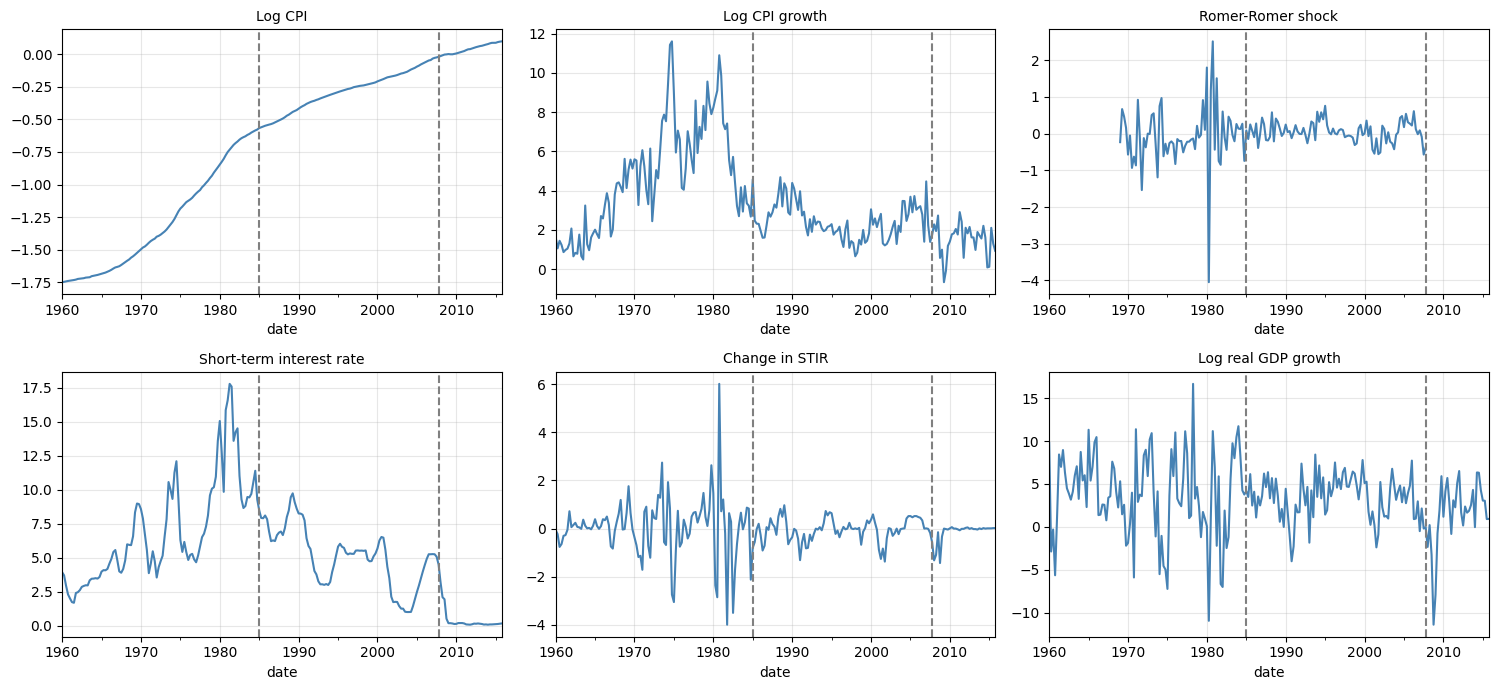

In [5]:
vars_to_plot = ['lcpi', 'dlcpi', 'rr_shock', 'stir', 'dstir', 'dlrgdp']

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, v in zip(axes.flat, vars_to_plot):
    raw[v].plot(ax=ax, color='steelblue', lw=1.5)
    ax.axvline(pd.Period('1985Q1', 'Q'), color='gray', ls='--')   # sample start
    ax.axvline(pd.Period('2007Q4', 'Q'), color='gray', ls='--')   # sample end
    ax.set_title(long_names.get(v, v), fontsize=10)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()





The log Consumer Price Index (CPI) exhibits a persistent upward trend, reflecting the cumulative increase in the US price level over time. Its first difference, log CPI growth, captures changes in the price level and shows considerably greater volatility, particularly during the 1970s and early 1980s, when US inflation was substantially higher.

The Romer-Romer monetary policy shock series displays variation in the unexpected component of monetary policy decisions. Large movements indicate quarters in which identified monetary policy shocks were particularly substantial. The short-term interest rate exhibits considerable variation during the earlier part of the sample, followed by a general decline over subsequent decades. Its first difference captures changes in the short-term interest rate rather than its level.

Finally, real GDP growth is considerably more volatile than the log GDP level, reflecting fluctuations in economic activity across quarters.

### Estimating Local Projections

We estimate the dynamic response of the log Consumer Price Index (CPI) to an identified Romer-Romer monetary policy shock over 18 quarterly horizons, from \(h=0\) to \(h=17\). At each horizon, the dependent variable measures the cumulative change in the log CPI relative to the quarter preceding the shock:

$$y_{t,h}=100\left(\log \text{CPI}_{t+h}-\log \text{CPI}_{t-1}\right)$$

Each horizon-specific regression controls for six lags of real GDP growth, CPI growth and changes in the short-term interest rate. We apply the Frisch-Waugh-Lovell theorem to residualise both the outcome and the monetary policy shock with respect to these controls, isolating the variation used to estimate the impulse response coefficients.

The resulting coefficients are estimated separately at each horizon using Ordinary Least Squares (OLS). We then construct a joint heteroskedasticity and autocorrelation consistent (HAC) covariance matrix using the Newey-West estimator with a Bartlett kernel and 17 lags. This accounts for serial dependence and cross-horizon covariance when calculating standard errors and conducting joint significance tests.

In [18]:
from scipy.stats import f as f_dist, norm

H5, NLAGS5, NW5 = 17, 6, 17
outcome5, shock5 = 'lcpi', 'rr_shock'
controls5 = ['dlrgdp', 'dlcpi', 'dstir']

stata_b5 = [0.03718, 0.0264991, -0.0701927, -0.0972651, -0.079699, -0.1669479,
            -0.3187805, -0.3860263, -0.4680645, -0.6422415, -0.8881057, -1.034987,
            -1.315287, -1.551731, -1.544292, -1.699767, -1.675823, -1.642865]
stata_se5 = [.0641234, .1574094, .1690445, .1925768, .2505888, .3330875,
             .3692985, .4436895, .5347268, .6352138, .6407504, .7056971,
             .7964428, .9330775, 1.013509, 1.034165, 1.024833, .9952787]

### Constructing Horizon-Specific Local Projection Estimates

We first construct six quarterly lags of each control variable: real GDP growth, CPI growth and changes in the short-term interest rate. This gives us 18 lagged control variables, which account for recent macroeconomic conditions preceding the monetary policy shock.

We then apply the Frisch-Waugh-Lovell (FWL) theorem to isolate the variation in the monetary policy shock that cannot be explained by these controls. We estimate the following auxiliary regression:

$$
RRShock_t = \alpha + \sum_{j=1}^{3}\sum_{l=1}^{6}\gamma_{jl}X_{j,t-l} + v_t
$$

The residuals, $\hat{v}_t$, represent the component of the monetary policy shock unexplained by the lagged controls.

Next, for each forecast horizon $h=0,\ldots,17$, we construct the cumulative change in the log CPI relative to the quarter preceding the shock:

$$
y_{t,h}=100(\log CPI_{t+h}-\log CPI_{t-1})
$$

We separately regress each horizon-specific outcome on the same lagged controls and extract the residuals, $\hat{u}_{t,h}$. We then match these residuals with the corresponding residualised monetary policy shocks and stack the observations across all 18 horizons.

The impulse response coefficient at each horizon is calculated as:

$$
\hat{\beta}_h =
\frac{\sum_t \hat{u}_{t,h}\hat{v}_t}
{\sum_t \hat{v}_t^2}
$$

This is the OLS coefficient obtained by regressing the residualised CPI outcome on the residualised monetary policy shock. It measures the cumulative CPI response to the shock at horizon $h$, conditional on the lagged controls.

Finally, we calculate the regression residuals:

$$
\hat{e}_{t,h}=\hat{u}_{t,h}-\hat{\beta}_h\hat{v}_t
$$

These residuals are subsequently used to construct the Newey-West heteroskedasticity and autocorrelation consistent (HAC) covariance matrix and calculate standard errors for the estimated impulse response coefficients.

In [19]:
lags5 = pd.concat(
    {f'{c}_L{l}': df[c].shift(l) for c in controls5 for l in range(1, NLAGS5 + 1)}, axis=1)

def resid5(y, X):
    return sm.OLS(y, sm.add_constant(X)).fit().resid

# shock residualised ONCE on the h=0 sample (86 obs)
tmp5 = pd.concat([df[shock5], lags5], axis=1).dropna()
rz5 = resid5(tmp5[shock5], tmp5.drop(columns=shock5))

pieces5 = []
for h in range(H5 + 1):
    y5 = (df[outcome5].shift(-h) - df[outcome5].shift(1)).rename('y')
    dh5 = pd.concat([y5, lags5], axis=1).dropna()
    ry5 = resid5(dh5['y'], dh5.drop(columns='y'))
    z5 = rz5.loc[ry5.index]
    pieces5.append(pd.DataFrame({
        'h': h, 't': ry5.index.to_timestamp(),
        'y': (ry5 - ry5.mean()).values, 'z': (z5 - z5.mean()).values}))
stack5 = pd.concat(pieces5, ignore_index=True)

num5 = (stack5['y'] * stack5['z']).groupby(stack5['h']).sum()
den5 = (stack5['z'] ** 2).groupby(stack5['h']).sum()
b5 = num5 / den5
stack5['e'] = stack5['y'] - stack5['h'].map(b5) * stack5['z']

### Newey-West HAC Covariance Matrix

We first calculate the moment contributions, $m_{t,h}=\hat{v}_t\hat{e}_{t,h}$, and arrange them into the time-by-horizon matrix `M5`. The cross-product `M5.T @ M5` captures contemporaneous covariance across horizons.

The loop adds lagged cross-products up to 17 quarters, weighted by the Bartlett kernel, to account for serial correlation. The resulting `S5` is the Newey-West HAC estimate of the covariance matrix of the moment contributions.

Next, `bread5` is a diagonal matrix containing the inverse sum of squared residualised shocks at each horizon. Premultiplying and postmultiplying `S5` by this matrix gives `V5`, the HAC covariance matrix of the impulse response estimates:

$$
V5 = bread5 \times S5 \times bread5
$$

In [20]:
M5 = (stack5.assign(m=stack5['z'] * stack5['e'])
            .pivot(index='t', columns='h', values='m')
            .sort_index().fillna(0).values)

S5 = M5.T @ M5
for l in range(1, NW5 + 1):
    G5 = M5[l:].T @ M5[:-l]
    S5 += (1 - l / (NW5 + 1)) * (G5 + G5.T)

bread5 = np.diag(1 / den5.values)
V5 = bread5 @ S5 @ bread5

### Finite-Sample Correction and Standard Errors

We calculate a finite-sample correction factor, `CORR5`, using the number of time periods (`T5`), stacked observations (`N5`) and estimated parameters (`K5`). This adjusts the HAC covariance matrix for finite-sample bias.

We apply the squared correction factor to `V5` to obtain the corrected covariance matrix, `V5c`. Finally, the square roots of its diagonal elements give `se5`, the HAC standard errors of the impulse response estimates.

In [21]:
T5, N5, K5 = M5.shape[0], len(stack5), H5 + 2
CORR5 = np.sqrt((T5 / (T5 - 1)) * ((N5 - 1) / (N5 - K5)))
V5c = V5 * CORR5 ** 2
se5 = np.sqrt(np.diag(V5c))

### Joint Significance Test

We conduct a joint Wald test of the null hypothesis that all 18 impulse response coefficients are zero:

$$
H_0:\beta_0=\beta_1=\cdots=\beta_{17}=0
$$

`F5` calculates the Wald statistic using the estimated coefficients, `b5`, and their corrected HAC covariance matrix, `V5c`. Dividing by 18 gives the corresponding F-statistic. `pval5` then calculates its p-value using an F-distribution with 18 numerator and 85 denominator degrees of freedom.

In [22]:
F5 = float(b5.values @ np.linalg.inv(V5c) @ b5.values / (H5 + 1))
pval5 = f_dist.sf(F5, H5 + 1, 85)


### Bonferroni-Adjusted Significance Band

We first residualise the contemporaneous CPI change and monetary policy shock against the lagged controls. The mean squared residualised shock, `mw5`, provides the denominator for the variance calculation.

We then calculate the product of the two residual series, `eta5`, and estimate its standard error using a Newey-West HAC regression with 17 lags. This gives `seta5`.

Finally, `band5` calculates the Bonferroni-adjusted critical value for a 5% significance level across all 18 horizons. It provides a common significance threshold for the impulse response estimates, accounting for multiple hypothesis testing.

In [23]:
y05 = (df[outcome5] - df[outcome5].shift(1)).rename('y')
d05 = pd.concat([y05, df[shock5], lags5], axis=1).dropna()
Xc5 = sm.add_constant(d05.drop(columns=['y', shock5]))
ry05 = sm.OLS(d05['y'], Xc5).fit().resid
rz05 = sm.OLS(d05[shock5], Xc5).fit().resid
mw5 = (rz05 ** 2).mean()
eta5 = ry05 * rz05
seta5 = sm.OLS(eta5, np.ones(len(eta5))).fit(
    cov_type='HAC', cov_kwds={'maxlags': NW5, 'use_correction': True}).bse.iloc[0]
band5 = norm.ppf(1 - 0.05 / (2 * (H5 + 1))) * seta5 / mw5

### Validation Against Stata Results

We compare the Python impulse response coefficients and HAC standard errors against the corresponding Stata estimates. We also check the number of stacked observations, effective time periods, finite-sample correction, joint Wald test and Bonferroni-adjusted significance band.

In [24]:
chk5 = pd.DataFrame({'python_b': b5.values, 'stata_b': stata_b5,
                     'python_se': se5, 'stata_se': stata_se5}, index=b5.index)
chk5['se_ratio'] = chk5['stata_se'] / chk5['python_se']

print(f"Stacked obs: {N5} (Stata 1395) | T = {T5} (expect 86) | CORR = {CORR5:.4f}")
print(f"Max |b diff|: {np.abs(chk5['python_b'] - chk5['stata_b']).max():.6f}")
print(f"se ratio range: {chk5['se_ratio'].min():.4f} to {chk5['se_ratio'].max():.4f}")
print(f"F = {F5:.2f} (Stata 13.02) | p = {pval5:.3g}")
print(f"mw = {mw5:.6f} (0.047764) | se(eta) = {seta5:.6f} (0.003062) | band = +/- {band5:.4f}")


Stacked obs: 1395 (Stata 1395) | T = 86 (expect 86) | CORR = 1.0124
Max |b diff|: 0.000001
se ratio range: 1.0000 to 1.0000
F = 13.02 (Stata 13.02) | p = 1.97e-17
mw = 0.047764 (0.047764) | se(eta) = 0.003062 (0.003062) | band = +/- 0.1918


### Replication Results

The Python estimates closely reproduce the Stata results. The maximum absolute difference in impulse response coefficients is 0.000001, and the standard error ratios are exactly 1.0000 across all horizons.

The joint Wald statistic is 13.02 ($p=1.97\times10^{-17}$), rejecting the null that all 18 impulse response coefficients are jointly zero. The contemporaneous moment variance, its HAC standard error and the Bonferroni-adjusted significance band also match the Stata benchmarks.



### Plotting the Impulse Response Function

We plot the estimated CPI response over horizons 0–16 quarters. The green line shows the impulse response coefficients, with shaded regions representing the 68% and 95% confidence intervals based on the HAC standard errors.

The horizontal black line marks zero response, while the blue dashed lines show the Bonferroni-adjusted significance thresholds.

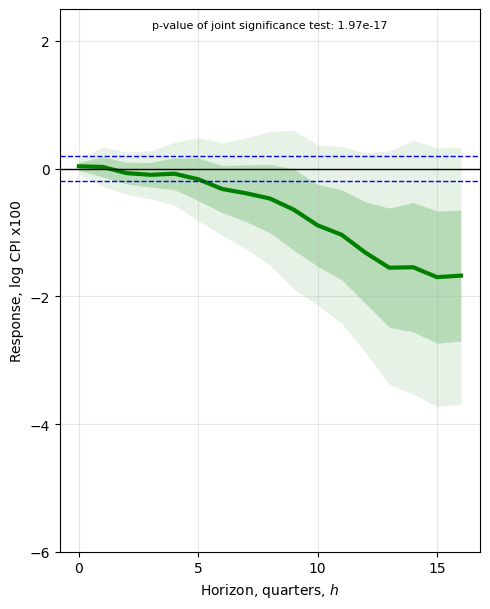

In [25]:
FIG_SIZE   = (5, 6.2)
COLOR      = 'green'
Y_LIM      = (-6, 2.5)
Y_TICKS    = range(-6, 3, 2)
X_TICKS    = [0, 5, 10, 15]
MAX_H      = 16            # Stata plots t = 0..16
SHOW_BAND  = True          # blue dashed significance bands
TITLE      = ''            # e.g. 'Figure 5a: CPI response to Romer-Romer shock'
SAVE_PATH  = '/content/drive/MyDrive/LocalProjections/Figure5a_python.png'

c95 = norm.ppf(0.975)
p5 = pd.DataFrame({'b': b5.values, 'se': se5}, index=b5.index).loc[:MAX_H]

fig, ax = plt.subplots(figsize=FIG_SIZE)
ax.fill_between(p5.index, p5.b - c95 * p5.se, p5.b + c95 * p5.se, color=COLOR, alpha=0.10, lw=0)  # 95%
ax.fill_between(p5.index, p5.b - p5.se, p5.b + p5.se, color=COLOR, alpha=0.20, lw=0)              # 68%
ax.plot(p5.index, p5.b, color=COLOR, lw=3)
ax.axhline(0, color='black', lw=1)
if SHOW_BAND:
    ax.axhline(band5, color='blue', ls='--', lw=1)
    ax.axhline(-band5, color='blue', ls='--', lw=1)
ax.set_xticks(X_TICKS); ax.set_yticks(list(Y_TICKS)); ax.set_ylim(*Y_LIM)
ax.set_xlabel('Horizon, quarters, $h$'); ax.set_ylabel('Response, log CPI x100')
ax.text(8, 2.2, f'p-value of joint significance test: {pval5:.3g}', ha='center', fontsize=8)
if TITLE:
    ax.set_title(TITLE, fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SAVE_PATH, dpi=200)
plt.show()


The solid green line plots the estimated impulse response coefficients. The response is initially close to zero but becomes increasingly negative over subsequent quarters, reaching approximately -1.7 percentage points by the final horizon. This indicates that a contractionary monetary policy shock is associated with a gradual decline in the price level relative to its pre-shock level.



## Figure 6: The Effects of Monetary Policy on Unemployment

This section replicates Figure 6 using monthly US data from January 1985 to January 2000. We estimate the dynamic response of the unemployment rate to a monetary policy shock using instrumental variables local projections (LP-IV).

The federal funds rate is treated as endogenous, while the Romer-Romer monetary policy shock serves as the baseline instrument. We use the contemporaneous shock and six monthly lags as instruments, controlling for six lags each of unemployment, inflation and the federal funds rate.

For each horizon $h=0,\ldots,48$, we estimate the cumulative change in unemployment relative to the month before the shock:

$$
u_{t+h}-u_{t-1}=\alpha_h+\beta_h ffr_t+\Gamma_h'X_{t-1}+\varepsilon_{t,h}
$$

where $ffr_t$ is the endogenous federal funds rate and $X_{t-1}$ contains the lagged controls. The federal funds rate is instrumented using the monetary policy shock and its six lags:

$$
Z_t=(RRCGShock_t,\ RRCGShock_{t-1},\ldots,RRCGShock_{t-6})
$$

We estimate the 49 horizon-specific coefficients using two-stage least squares (2SLS). Newey-West HAC standard errors account for heteroskedasticity and serial correlation.



We load the monthly data from the `Ex6` worksheet and convert the dates into a monthly time index. We restrict the estimation sample to January 1985–January 2000 **before constructing any lags or leads**, ensuring that subsequent regressions use the same sample period as the Stata implementation.

We check the number of observations and missing values in the five variables used in the analysis. The four-panel figure plots the historical unemployment rate, inflation, federal funds rate and Romer-Romer monetary policy shock. The dashed vertical lines mark the estimation sample boundaries.

/tmp/ipykernel_7728/1394822921.py:7: FutureWarning: Constructing PeriodIndex from fields is deprecated. Use PeriodIndex.from_fields instead.
  raw6.index = pd.PeriodIndex(year=ym[0], month=ym[1], freq='M')


Observations (expect 181): 181
urate            0
infl             0
ffr              0
RRCGShock        0
KuttnerShock    53
dtype: int64


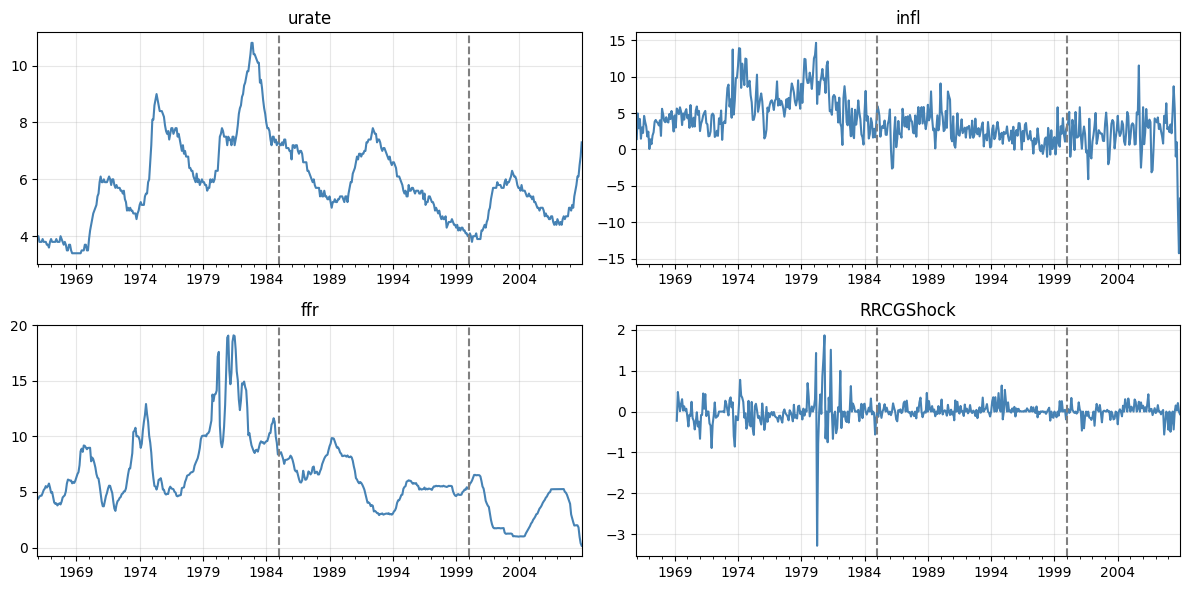

In [26]:
raw6 = pd.read_excel(PATH, sheet_name='Ex6', header=1)
raw6 = raw6.rename(columns={raw6.columns[0]: 'date'})
raw6.columns = raw6.columns.str.strip()

# Dates look like '1965m12'
ym = raw6['date'].astype(str).str.lower().str.split('m', expand=True).astype(int)
raw6.index = pd.PeriodIndex(year=ym[0], month=ym[1], freq='M')
raw6 = raw6.drop(columns='date')

# Cut the sample BEFORE building lags/leads (same as Stata)
df6 = raw6.loc['1985-01':'2000-01'].copy()
print("Observations (expect 181):", len(df6))
print(df6[['urate', 'infl', 'ffr', 'RRCGShock', 'KuttnerShock']].isna().sum())

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, v in zip(axes.flat, ['urate', 'infl', 'ffr', 'RRCGShock']):
    raw6[v].plot(ax=ax, color='steelblue', lw=1.5)
    ax.axvline(pd.Period('1985-01', 'M'), color='gray', ls='--')
    ax.axvline(pd.Period('2000-01', 'M'), color='gray', ls='--')
    ax.set_title(v); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The restricted sample contains 181 monthly observations, matching the Stata sample. The unemployment rate, inflation, federal funds rate and Romer-Romer shock have no missing observations. The Kuttner shock contains 53 missing observations, which must be accounted for when estimating specifications that use this alternative monetary policy shock.

The unemployment rate (urate) exhibits cyclical behavior, peaking during recessions (such as the early 1980s) and declining during expansions. Inflation (infl) captures changes in the price level and shows considerably greater volatility, particularly during the 1970s and early 1980s, when US inflation was substantially higher.

The federal funds rate (ffr) exhibits considerable variation during the earlier part of the sample: peaking above 15% in the late 1970s and early 1980s, followed by a general downward trend over subsequent decades. The Romer-Romer monetary policy shock series (RRCGShock) displays variation in the unexpected component of monetary policy decisions, where large movements indicate quarters in which identified monetary policy shocks were particularly substantial.


### Local Projection Specification

We set the maximum impulse response horizon to 48 months and include six monthly lags of each control variable: unemployment, inflation and the federal funds rate. The Newey-West HAC estimator uses six lags to account for serial correlation.

The baseline specification uses the Romer-Romer monetary policy shock (`RRCGShock`) as the instrument, the unemployment rate (`urate`) as the outcome and the federal funds rate (`ffr`) as the endogenous variable. The Kuttner shock can be selected as an alternative instrument.

We also load the Stata impulse response coefficients, standard errors and joint test statistics as benchmarks for validating the Python replication.

In [27]:
from scipy.stats import chi2 as chi2_dist

H6, NLAGS6, NW6 = 48, 6, 6
INSTRUMENT6 = 'RRCGShock'            # 'KuttnerShock' for the extension (validation then skipped)
OUTCOME6, ENDOG6 = 'urate', 'ffr'
CTRL6 = ['urate', 'infl', 'ffr']


In [28]:
stata_b6 = np.array([
 -0.1064262, -0.2771184, -0.1369168, -0.30783, -0.2280762, 0.0349409, -0.0056199,
 0.100621, 0.1266621, 0.2364699, 0.4033873, 0.5381533, 0.5956524, 0.696255,
 0.7395653, 0.7076371, 0.7151173, 0.7841655, 0.7359816, 0.6602048, 1.00828,
 0.8418757, 0.955757, 1.034495, 0.9247739, 1.125736, 1.180552, 1.184316,
 1.209144, 1.137771, 1.064054, 1.222096, 1.16556, 1.011409, 0.9897325,
 0.7812856, 0.5905552, 0.4857201, 0.337699, 0.2231293, 0.3512862, 0.2819391,
 0.3120592, 0.312511, 0.1635823, 0.1634476, 0.1822017, 0.2303366, 0.1773445])
stata_se6 = np.array([
 .1036342, .1451333, .2136324, .2145274, .2428301, .2647035, .2852908,
 .3070373, .3138764, .3635988, .3358279, .3281796, .3595545, .3919792,
 .4065518, .4148614, .3847041, .3862919, .393052, .3961197, .4277655,
 .4446494, .453127, .4727848, .4855744, .484996, .497031, .5091533,
 .5196768, .5181528, .521871, .5024369, .5282765, .5211762, .4771729,
 .4845382, .4932678, .486323, .5245328, .5210293, .5018647, .5703598,
 .5717282, .521591, .5536545, .519548, .5391916, .5751769, .6266192])
STATA_CHI2_6, STATA_N6 = 446.89, 121

### Constructing Lagged Controls and Residualisation Function

We define a function that residualises a variable by regressing it on a constant and the specified controls using OLS. Rows with missing values are excluded, and the function returns the regression residuals while preserving their monthly time index.

In [31]:
def resid6(y, X):
    """OLS residuals of y on a constant and X, using only rows with no missing values."""
    dd = pd.concat([y.rename('y'), X], axis=1).dropna()
    Xc = np.column_stack([np.ones(len(dd)), dd[X.columns].to_numpy()])
    beta = np.linalg.lstsq(Xc, dd['y'].to_numpy(), rcond=None)[0]
    return pd.Series(dd['y'].to_numpy() - Xc @ beta, index=dd.index)

ctrl6 = pd.concat(
    {f'{c}_L{l}': df6[c].shift(l) for c in CTRL6 for l in range(1, NLAGS6 + 1)}, axis=1)


For each horizon from 0 to 48 months, we calculate the cumulative change in the unemployment rate relative to the month before the monetary policy shock. We then residualise each outcome against the 18 lagged controls using OLS.

Each horizon is estimated on its own available sample because longer horizons require more future observations. This produces the residualised outcomes used to estimate the impulse response coefficients.

In [30]:
ry6 = pd.concat(
    {f'y{h}': resid6(df6[OUTCOME6].shift(-h) - df6[OUTCOME6].shift(1), ctrl6)
     for h in range(H6 + 1)}, axis=1)


### Residualising the Endogenous Variable and Instrument

We residualise the federal funds rate (`ffr`) and the selected monetary policy instrument against the lagged controls, obtaining `rffr6` and `rz6`. Both are residualised once using their available sample.

We then construct six monthly lags of the residualised instrument (`rzl6`). These lagged instrument terms are used in the subsequent IV estimation to account for the dynamic relationship between monetary policy shocks and the endogenous federal funds rate.

In [32]:
rffr6 = resid6(df6[ENDOG6], ctrl6).reindex(df6.index)
rz6   = resid6(df6[INSTRUMENT6], ctrl6).reindex(df6.index)
rzl6  = pd.concat({f'z{l}': rz6.shift(l) for l in range(1, NLAGS6 + 1)}, axis=1)


We combine the 49 horizon-specific residualised outcomes, the residualised federal funds rate and the contemporaneous and six lagged residualised instruments. Dropping missing observations creates a common estimation sample for all 49 equations.

We then construct the matrices required for 2SLS estimation. `Y6` contains the 49 outcome variables, `x6` contains the endogenous federal funds rate, and `Z6` contains the instrument set: a constant, the contemporaneous instrument and its six lags. `X6` contains the endogenous variable and a constant.

This gives 49 outcomes, one endogenous regressor and seven excluded instruments, estimated on the same sample.

In [33]:
d6 = pd.concat([ry6, rffr6.rename('x'), rz6.rename('z0'), rzl6], axis=1).dropna()
N6 = len(d6)

Y6 = d6[[f'y{h}' for h in range(H6 + 1)]].to_numpy()                       # N x 49
x6 = d6['x'].to_numpy()
Z6 = np.column_stack([np.ones(N6), d6[['z0'] + list(rzl6.columns)].to_numpy()])   # N x 8
X6 = np.column_stack([x6, np.ones(N6)])                                    # [ffr, constant]


### Estimating the Impulse Responses Using 2SLS

We estimate all 49 horizon-specific impulse responses using two-stage least squares (2SLS).

The code constructs the 2SLS weighting and projection matrices, then estimates the coefficients for all 49 outcome horizons simultaneously. `theta6` contains the estimated coefficients on the federal funds rate and the constant; `b6` extracts the 49 impulse response coefficients, from $h=0$ to $h=48$.

In [34]:
A6 = np.linalg.inv(Z6.T @ Z6 / N6)
G6 = Z6.T @ X6 / N6                                                        # 8 x 2
M6 = np.linalg.solve(G6.T @ A6 @ G6, G6.T @ A6)                            # 2 x 8
theta6 = M6 @ (Z6.T @ Y6 / N6)                                             # 2 x 49
b6 = theta6[0]                                                             # b_0 ... b_48


### Joint HAC Covariance Matrix and Wald Test

We first calculate the 2SLS residuals for all 49 horizons. We then construct the instrument-residual moment contributions and arrange them into a matrix, `m6`. The cross-product matrix captures contemporaneous covariance across horizons.

The loop adds lagged cross-products up to six months, applying Bartlett weights to account for serial correlation. This produces the joint Newey-West HAC covariance matrix, `S6`.

We then use the 2SLS coefficient mapping matrix, `B6`, to obtain the covariance matrix of all estimated coefficients. `Vb6` extracts the covariance matrix for the 49 federal funds rate coefficients, and the square roots of its diagonal elements give their HAC standard errors, `se6`.

Finally, we conduct a joint Wald test of the null hypothesis that all 49 impulse response coefficients are zero. `wald6` is the Wald statistic, and `pval6` is its p-value from a chi-squared distribution with 49 degrees of freedom.

In [35]:
E6 = Y6 - X6 @ theta6
m6 = (Z6[:, None, :] * E6[:, :, None]).reshape(N6, -1)                     # N x 392
S6 = m6.T @ m6 / N6
for l in range(1, NW6 + 1):
    Gl6 = m6[l:].T @ m6[:-l] / N6
    S6 += (1 - l / (NW6 + 1)) * (Gl6 + Gl6.T)

B6 = np.kron(np.eye(H6 + 1), M6)                                           # 98 x 392
V6 = B6 @ S6 @ B6.T / N6
Vb6 = V6[0::2, 0::2]                                                       # cov of b_0 ... b_48
se6 = np.sqrt(np.diag(Vb6))


In [36]:
wald6 = float(b6 @ np.linalg.solve(Vb6, b6))
pval6 = chi2_dist.sf(wald6, H6 + 1)


### First-Stage Instrument Strength and Estimation Summary

We estimate the first-stage regression of the endogenous federal funds rate on the instrument set using OLS. The non-robust first-stage F-statistic tests whether the seven excluded instruments (the contemporaneous monetary policy shock and its six lags) are jointly significant.



In [37]:
fs6 = np.linalg.lstsq(Z6, x6, rcond=None)[0]
rss_u6, rss_r6 = ((x6 - Z6 @ fs6) ** 2).sum(), ((x6 - x6.mean()) ** 2).sum()
F1_6 = ((rss_r6 - rss_u6) / 7) / (rss_u6 / (N6 - 8))

print(f"Instrument: {INSTRUMENT6} | N = {N6} | sample {d6.index[0]} to {d6.index[-1]}")
print(f"Wald chi2(49) = {wald6:.2f} | p = {pval6:.3g} | first-stage F (non-robust) = {F1_6:.1f}")


Instrument: RRCGShock | N = 121 | sample 1986-01 to 1996-01
Wald chi2(49) = 446.89 | p = 1.3e-65 | first-stage F (non-robust) = 6.0


The common estimation sample contains 121 monthly observations, spanning January 1986 to January 1996. The joint Wald test strongly rejects the null that all 49 impulse response coefficients are zero ($\chi^2(49)=446.89$, $p=1.3\times10^{-65}$).

The first-stage F-statistic is 6.0, indicating that the instruments have limited predictive power for the federal funds rate. This raises a potential weak-instrument concern and warrants caution when interpreting the 2SLS estimates.

### Validation Against Stata Results

For the baseline Romer-Romer instrument specification, we compare the Python 2SLS impulse response coefficients and HAC standard errors against the Stata reference estimates. We also verify that the common estimation sample and joint Wald statistic match.

In [38]:
if INSTRUMENT6 == 'RRCGShock':
    chk6 = pd.DataFrame({'python_b': b6, 'stata_b': stata_b6,
                         'python_se': se6, 'stata_se': stata_se6})
    chk6['se_ratio'] = chk6['stata_se'] / chk6['python_se']
    print(f"N = {N6} (Stata {STATA_N6}) | chi2 = {wald6:.2f} (Stata {STATA_CHI2_6})")
    print(f"Max |b diff|: {np.abs(chk6['python_b'] - chk6['stata_b']).max():.6f}")
    print(f"se ratio range: {chk6['se_ratio'].min():.4f} to {chk6['se_ratio'].max():.4f}")
else:
    print("Validation skipped: Stata reference numbers exist only for RRCGShock.")


N = 121 (Stata 121) | chi2 = 446.89 (Stata 446.89)
Max |b diff|: 0.000000
se ratio range: 1.0000 to 1.0000


### Replication Results

The Python estimates exactly reproduce the Stata results. Both implementations use 121 observations and produce the same joint Wald statistic of 446.89. The maximum absolute difference in impulse response coefficients is zero, and the standard error ratios are 1.0000 across all 49 horizons.

This confirms that the Python implementation successfully replicates the Stata 2SLS estimates and joint HAC inference for the baseline specification.

### Plotting Figure 6: Unemployment Response to a Monetary Policy Shock

We plot the estimated unemployment response over horizons 0–47 months, with shaded regions showing the 68% and 95% confidence intervals based on the HAC standard errors. The blue dashed line represents the impulse response, and the black horizontal line marks zero.

The `AS_PUBLISHED` setting controls the horizon indexing. When set to `True`, the code reproduces the published figure's indexing convention, which plots coefficients $\hat{\beta}_1,\ldots,\hat{\beta}_{48}$ at horizons 0–47. When set to `False`, it plots $\hat{\beta}_0,\ldots,\hat{\beta}_{47}$ at their actual horizons. The figure also reports the joint Wald test of all 49 impulse response coefficients.

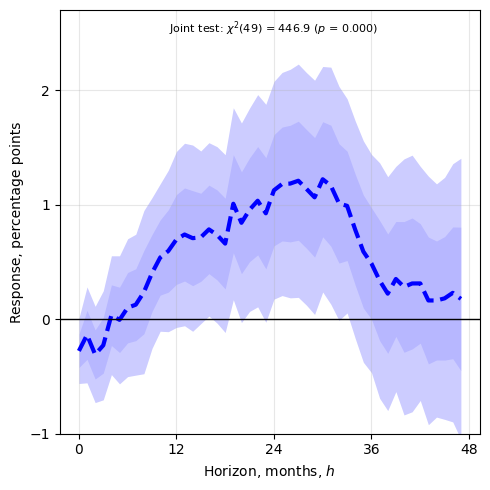

In [40]:
AS_PUBLISHED = True
FIG_SIZE   = (5, 5)
COLOR      = 'blue'
Y_LIM      = (-1, 2.7)
Y_TICKS    = [-1, 0, 1, 2]
X_TICKS    = range(0, 49, 12)
MAX_T      = 48         # Stata plots t < 48
TITLE      = ''         # e.g. 'Figure 6a: Unemployment response (LP-IV)'
SAVE_PATH  = ('/content/drive/MyDrive/LocalProjections/Figure6a_python_'
              + ('published' if AS_PUBLISHED else 'corrected') + '.png')

t6   = np.arange(MAX_T)
idx6 = np.arange(1, MAX_T + 1) if AS_PUBLISHED else np.arange(0, MAX_T)
bp6, sp6 = b6[idx6], se6[idx6]

fig, ax = plt.subplots(figsize=FIG_SIZE)
ax.fill_between(t6, bp6 - sp6, bp6 + sp6, color=COLOR, alpha=0.10, lw=0)               # 68%: lighter
ax.fill_between(t6, bp6 - 1.96 * sp6, bp6 + 1.96 * sp6, color=COLOR, alpha=0.20, lw=0) # 95%: darker
ax.plot(t6, bp6, color=COLOR, ls='--', lw=3)
ax.axhline(0, color='black', lw=1)
ax.set_xticks(list(X_TICKS)); ax.set_yticks(Y_TICKS); ax.set_ylim(*Y_LIM)
ax.set_xlabel('Horizon, months, $h$'); ax.set_ylabel('Response, percentage points')
ax.text(24, 2.5, rf'Joint test: $\chi^2$(49) = {wald6:.1f} ($p$ = {pval6:.3f})',
        ha='center', fontsize=8)
if TITLE:
    ax.set_title(TITLE, fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SAVE_PATH, dpi=200)
plt.show()